Using local file: 'hurdat2.csv'
Post-filtering (Year >= 1975): 20,184 observations across 696 cyclones.

Training Intensity Prediction Model Suites...
--> Training Random Forest across [ΔVmax, ΔPmin, ΔLat, ΔLon]...


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

--> Training KNN across [ΔVmax, ΔPmin, ΔLat, ΔLon]...
--> Training XGBoost across [ΔVmax, ΔPmin, ΔLat, ΔLon]...

Simulating 48h intensity forecast for test storm: AL032000


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

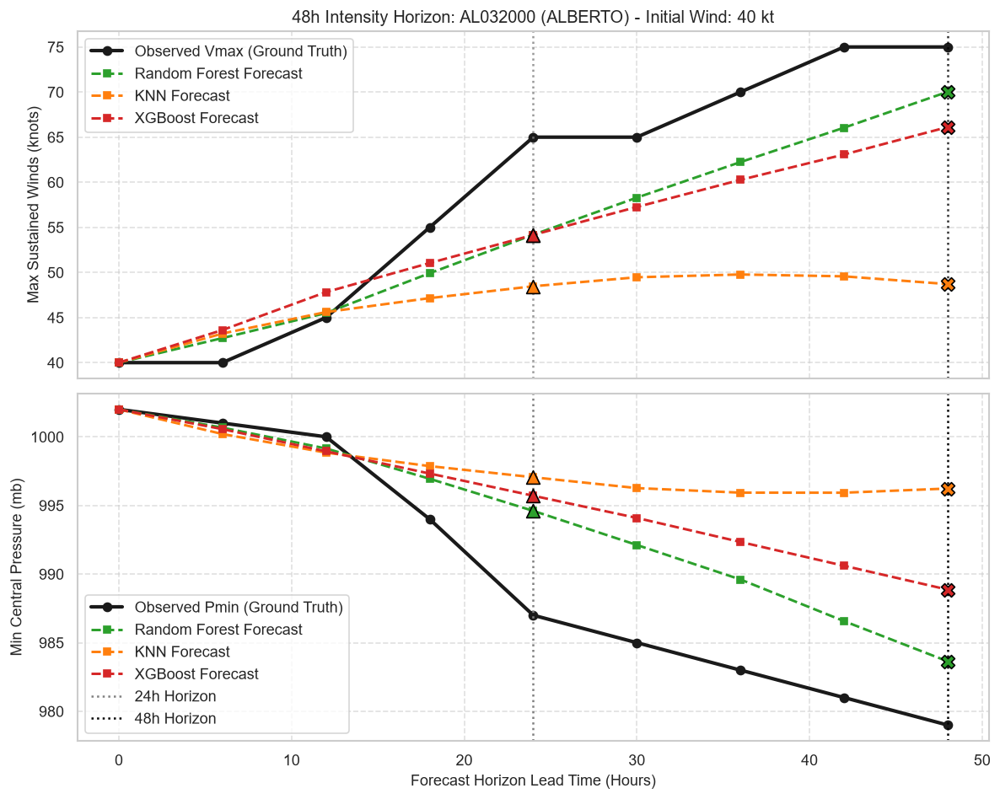


Computing Intensity MAE across 48h forecast horizons...


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

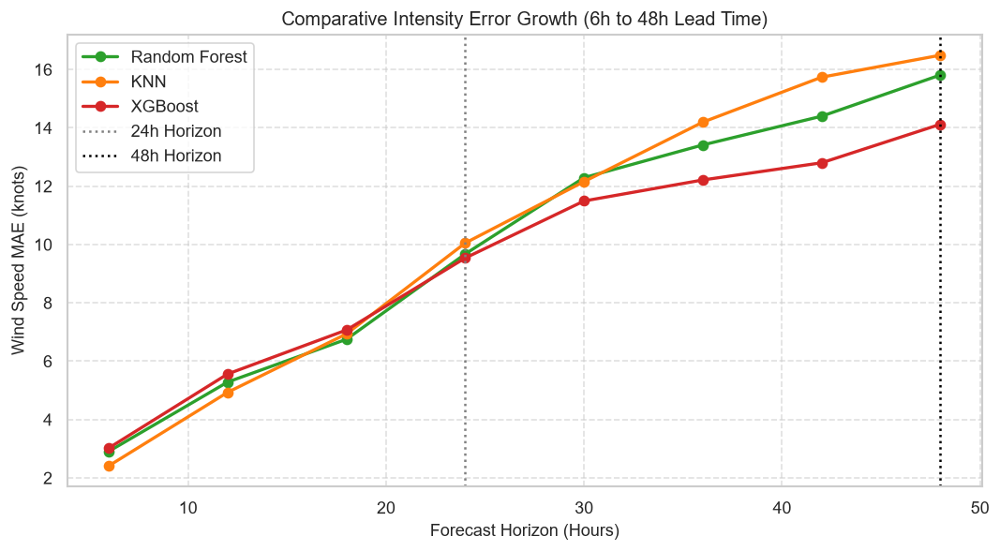

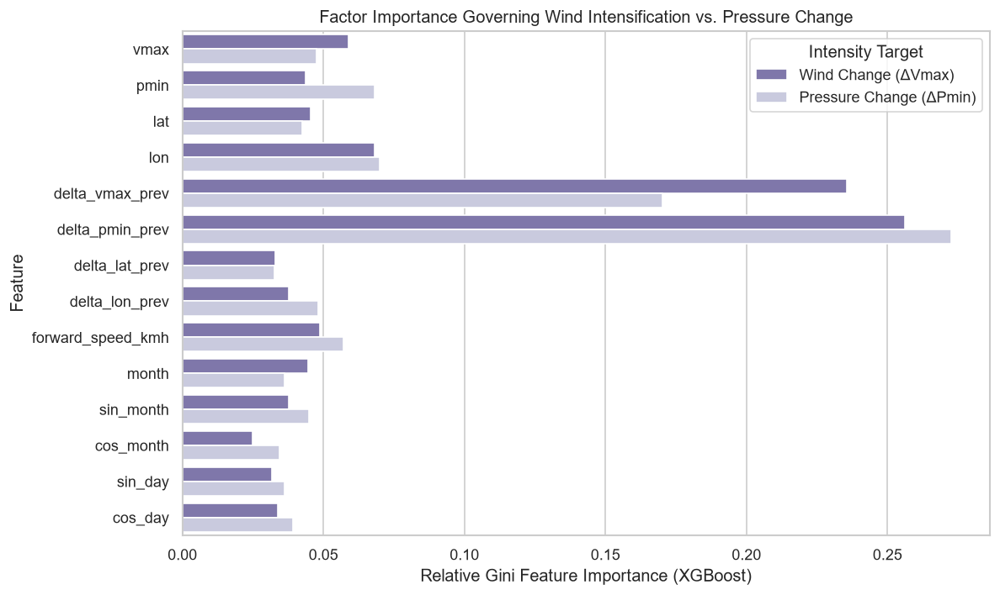

Computing TreeSHAP dependency for intensity dynamics...


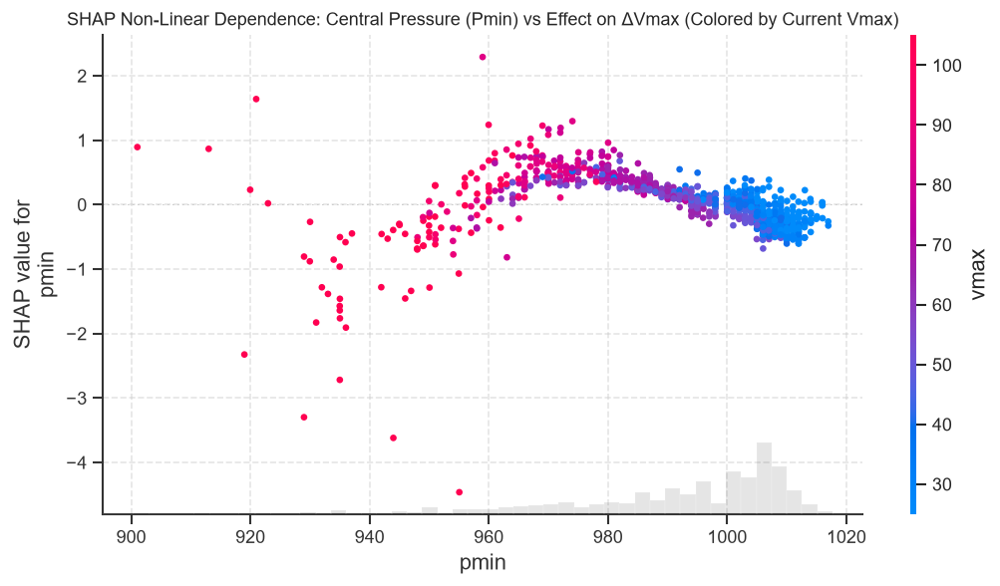

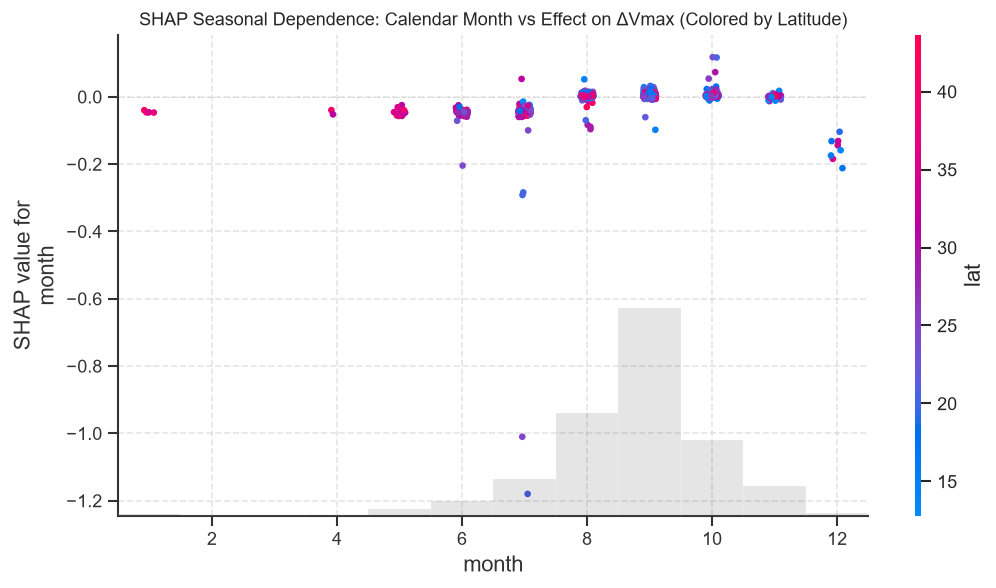

In [7]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
import shap

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

HURDAT_URL = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2023-051124.txt"
LOCAL_CSV = "hurdat2.csv"

# ==============================================================================
# 1. INGESTION, QUALITY FILTERING & INTENSITY FEATURE ENGINEERING
# ==============================================================================

def download_dataset(filepath: str = LOCAL_CSV):
    """Downloads HURDAT2 archive from NOAA NHC if missing."""
    if not os.path.exists(filepath):
        print(f"Downloading HURDAT2 to '{filepath}'...")
        urllib.request.urlretrieve(HURDAT_URL, filepath)
        print("Download complete.")
    else:
        print(f"Using local file: '{filepath}'")


def parse_and_clean_hurdat2(filepath: str, min_year: int = 1975) -> pd.DataFrame:
    """
    Parses HURDAT2, excluding pre-satellite records (<1975) and -999/999 sentinels.
    """
    records = []
    current_id, current_name = None, None

    with open(filepath, "r") as f:
        for line in f:
            tokens = [t.strip() for t in line.split(",")]
            if len(tokens) >= 3 and tokens[0].startswith(("AL", "EP", "CP")):
                current_id = tokens[0]
                current_name = tokens[1]
            elif len(tokens) >= 8 and current_id is not None:
                date_str = tokens[0]
                time_str = tokens[1]
                status = tokens[3]
                lat_raw = tokens[4]
                lon_raw = tokens[5]

                try:
                    vmax = float(tokens[6])
                    pmin = float(tokens[7])
                except ValueError:
                    continue

                year = int(date_str[:4])
                if year < min_year:
                    continue

                # Filter sentinel flags
                if pmin in [-999.0, 999.0, -99.0] or pmin < 850.0 or pmin > 1040.0:
                    continue
                if vmax in [-999.0, 999.0, -99.0] or vmax <= 0.0:
                    continue

                lat = float(lat_raw[:-1]) * (-1.0 if lat_raw.endswith("S") else 1.0)
                lon = float(lon_raw[:-1]) * (-1.0 if lon_raw.endswith("W") else 1.0)

                records.append({
                    "storm_id": current_id,
                    "storm_name": current_name,
                    "timestamp": pd.to_datetime(f"{date_str} {time_str}", format="%Y%m%d %H%M"),
                    "lat": lat,
                    "lon": lon,
                    "vmax": vmax,
                    "pmin": pmin,
                    "status": status
                })

    df = pd.DataFrame(records)
    print(f"Post-filtering (Year >= {min_year}): {len(df):,} observations across {df['storm_id'].nunique():,} cyclones.")
    return df


def haversine_vectorized(lat1, lon1, lat2, lon2) -> np.ndarray:
    """Vectorized Great-Circle distance in kilometers."""
    R = 6371.0
    p1, l1, p2, l2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dp = p2 - p1
    dl = l2 - l1
    a = np.sin(dp / 2.0)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2.0)**2
    c = 2 * np.arcsin(np.clip(np.sqrt(a), 0.0, 1.0))
    return R * c


def engineer_intensity_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Extracts intensity derivatives, forward delta targets, forward translation speed,
    and cyclical seasonal components.
    """
    df = df.sort_values(by=["storm_id", "timestamp"]).reset_index(drop=True)

    # 1. Forward Intensity Targets (6-hour changes)
    df["delta_vmax_next"] = df.groupby("storm_id")["vmax"].shift(-1) - df["vmax"]
    df["delta_pmin_next"] = df.groupby("storm_id")["pmin"].shift(-1) - df["pmin"]

    # Trajectory delta targets for recursive joint propagation
    df["delta_lat_next"] = df.groupby("storm_id")["lat"].shift(-1) - df["lat"]
    df["delta_lon_next"] = df.groupby("storm_id")["lon"].shift(-1) - df["lon"]

    # 2. Historical Intensification Rates (Prior 6 hours)
    df["delta_vmax_prev"] = df["vmax"] - df.groupby("storm_id")["vmax"].shift(1)
    df["delta_pmin_prev"] = df["pmin"] - df.groupby("storm_id")["pmin"].shift(1)
    df["delta_lat_prev"] = df["lat"] - df.groupby("storm_id")["lat"].shift(1)
    df["delta_lon_prev"] = df["lon"] - df.groupby("storm_id")["lon"].shift(1)

    # Forward translation speed (km/h over 6 hours)
    prev_lat = df.groupby("storm_id")["lat"].shift(1)
    prev_lon = df.groupby("storm_id")["lon"].shift(1)
    df["forward_speed_kmh"] = haversine_vectorized(prev_lat, prev_lon, df["lat"], df["lon"]) / 6.0

    # 3. Temporal & Seasonal Features
    month = df["timestamp"].dt.month
    df["month"] = month
    df["sin_month"] = np.sin(2 * np.pi * month / 12.0)
    df["cos_month"] = np.cos(2 * np.pi * month / 12.0)

    doy = df["timestamp"].dt.dayofyear
    df["sin_day"] = np.sin(2 * np.pi * doy / 365.25)
    df["cos_day"] = np.cos(2 * np.pi * doy / 365.25)

    # Filter invalid boundaries and require >= 9 steps for 48h horizon verification
    clean_df = df.dropna(subset=[
        "delta_vmax_prev", "delta_pmin_prev", "delta_lat_prev", "delta_lon_prev",
        "forward_speed_kmh", "delta_vmax_next", "delta_pmin_next",
        "delta_lat_next", "delta_lon_next"
    ]).copy()

    counts = clean_df["storm_id"].value_counts()
    valid_storms = counts[counts >= 9].index
    clean_df = clean_df[clean_df["storm_id"].isin(valid_storms)].reset_index(drop=True)

    return clean_df


# ==============================================================================
# 2. MODEL SUITE TRAINING (RANDOM FOREST, KNN, XGBOOST)
# ==============================================================================

def train_intensity_models(clean_df: pd.DataFrame):
    feature_cols = [
        "vmax", "pmin", "lat", "lon",
        "delta_vmax_prev", "delta_pmin_prev",
        "delta_lat_prev", "delta_lon_prev",
        "forward_speed_kmh",
        "month", "sin_month", "cos_month",
        "sin_day", "cos_day"
    ]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    train_idx, test_idx = next(splitter.split(clean_df, groups=clean_df["storm_id"]))

    train_df = clean_df.iloc[train_idx]
    test_df = clean_df.iloc[test_idx]

    X_train = train_df[feature_cols]

    models = {
        "Random Forest": {
            "dvmax": RandomForestRegressor(n_estimators=120, max_depth=12, n_jobs=-1, random_state=42),
            "dpmin": RandomForestRegressor(n_estimators=120, max_depth=12, n_jobs=-1, random_state=42),
            "dlat": RandomForestRegressor(n_estimators=80, max_depth=10, n_jobs=-1, random_state=42),
            "dlon": RandomForestRegressor(n_estimators=80, max_depth=10, n_jobs=-1, random_state=42)
        },
        "KNN": {
            "dvmax": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20, weights="distance")),
            "dpmin": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20, weights="distance")),
            "dlat": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20, weights="distance")),
            "dlon": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20, weights="distance"))
        },
        "XGBoost": {
            "dvmax": XGBRegressor(n_estimators=180, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "dpmin": XGBRegressor(n_estimators=180, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "dlat": XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "dlon": XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
        }
    }

    print("\nTraining Intensity Prediction Model Suites...")
    for name, sub in models.items():
        print(f"--> Training {name} across [ΔVmax, ΔPmin, ΔLat, ΔLon]...")
        sub["dvmax"].fit(X_train, train_df["delta_vmax_next"])
        sub["dpmin"].fit(X_train, train_df["delta_pmin_next"])
        sub["dlat"].fit(X_train, train_df["delta_lat_next"])
        sub["dlon"].fit(X_train, train_df["delta_lon_next"])

    return models, train_df, test_df, feature_cols


# ==============================================================================
# 3. 24h - 48h BOUNDED INTENSITY ROLLOUT
# ==============================================================================

def simulate_bounded_intensity(sub_models, initial_row: pd.Series, feature_cols: list, max_steps: int = 8) -> np.ndarray:
    """
    Rolls out intensity recursively for up to max_steps (8 steps = 48h).
    Returns array: [[lead_hour, vmax, pmin], ...]
    """
    state = initial_row.to_dict()
    records = [(0, state["vmax"], state["pmin"])]

    for step in range(1, max_steps + 1):
        row_input = pd.DataFrame([{col: state[col] for col in feature_cols}])

        dvmax = float(sub_models["dvmax"].predict(row_input)[0])
        dpmin = float(sub_models["dpmin"].predict(row_input)[0])
        dlat = float(sub_models["dlat"].predict(row_input)[0])
        dlon = float(sub_models["dlon"].predict(row_input)[0])

        # State updates
        old_lat, old_lon = state["lat"], state["lon"]
        state["lat"] += dlat
        state["lon"] += dlon
        state["vmax"] = max(10.0, state["vmax"] + dvmax)
        state["pmin"] = min(1030.0, max(860.0, state["pmin"] + dpmin))

        # Kinematic updates
        state["delta_vmax_prev"] = dvmax
        state["delta_pmin_prev"] = dpmin
        state["delta_lat_prev"] = dlat
        state["delta_lon_prev"] = dlon
        state["forward_speed_kmh"] = haversine_vectorized(old_lat, old_lon, state["lat"], state["lon"]) / 6.0

        records.append((step * 6, state["vmax"], state["pmin"]))

    return np.array(records)


# ==============================================================================
# 4. INTENSITY VISUALIZATIONS & FACTOR DEPENDENCIES
# ==============================================================================

def plot_intensity_horizon_comparison(test_df: pd.DataFrame, models: dict, feature_cols: list, storm_id: str, start_index: int = 2):
    """
    Visualizes Vmax and Pmin 48h projections against ground truth observations.
    """
    storm_subset = test_df[test_df["storm_id"] == storm_id].sort_values("timestamp").reset_index(drop=True)
    if len(storm_subset) < (start_index + 9):
        print(f"Not enough points in {storm_id} for 48h rollout from index {start_index}.")
        return

    init_row = storm_subset.iloc[start_index]
    actual_series = storm_subset.iloc[start_index:start_index + 9][["vmax", "pmin"]].to_numpy()
    lead_hours = np.arange(0, 9) * 6

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, dpi=120)
    colors = {"Random Forest": "#2ca02c", "KNN": "#ff7f0e", "XGBoost": "#d62728"}

    # 1. Maximum Sustained Wind (Vmax) Plot
    ax1.plot(lead_hours, actual_series[:, 0], "k-o", linewidth=2.5, markersize=6, label="Observed Vmax (Ground Truth)")
    for name, sub in models.items():
        sim = simulate_bounded_intensity(sub, init_row, feature_cols, max_steps=8)
        ax1.plot(sim[:, 0], sim[:, 1], "--s", color=colors[name], linewidth=1.8, markersize=5, label=f"{name} Forecast")
        # 24h & 48h markers
        ax1.scatter(sim[4, 0], sim[4, 1], color=colors[name], s=90, marker="^", edgecolors="black", zorder=5)
        ax1.scatter(sim[8, 0], sim[8, 1], color=colors[name], s=90, marker="X", edgecolors="black", zorder=5)

    ax1.axvline(24, color="gray", linestyle=":", alpha=0.8)
    ax1.axvline(48, color="black", linestyle=":", alpha=0.8)
    ax1.set_ylabel("Max Sustained Winds (knots)", fontsize=11)
    ax1.set_title(f"48h Intensity Horizon: {storm_id} ({init_row['storm_name']}) - Initial Wind: {int(init_row['vmax'])} kt", fontsize=12)
    ax1.legend(loc="upper left")
    ax1.grid(True, linestyle="--", alpha=0.6)

    # 2. Minimum Central Pressure (Pmin) Plot
    ax2.plot(lead_hours, actual_series[:, 1], "k-o", linewidth=2.5, markersize=6, label="Observed Pmin (Ground Truth)")
    for name, sub in models.items():
        sim = simulate_bounded_intensity(sub, init_row, feature_cols, max_steps=8)
        ax2.plot(sim[:, 0], sim[:, 2], "--s", color=colors[name], linewidth=1.8, markersize=5, label=f"{name} Forecast")
        ax2.scatter(sim[4, 0], sim[4, 2], color=colors[name], s=90, marker="^", edgecolors="black", zorder=5)
        ax2.scatter(sim[8, 0], sim[8, 2], color=colors[name], s=90, marker="X", edgecolors="black", zorder=5)

    ax2.axvline(24, color="gray", linestyle=":", label="24h Horizon")
    ax2.axvline(48, color="black", linestyle=":", label="48h Horizon")
    ax2.set_xlabel("Forecast Horizon Lead Time (Hours)", fontsize=11)
    ax2.set_ylabel("Min Central Pressure (mb)", fontsize=11)
    ax2.legend(loc="lower left")
    ax2.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()


def plot_intensity_error_growth(test_df: pd.DataFrame, models: dict, feature_cols: list, num_samples: int = 50):
    """
    Computes and plots Wind Speed MAE (knots) across lead horizons (6h to 48h).
    """
    print("\nComputing Intensity MAE across 48h forecast horizons...")
    eligible_storms = [sid for sid, grp in test_df.groupby("storm_id") if len(grp) >= 12]
    np.random.seed(42)
    sample_storms = np.random.choice(eligible_storms, size=min(num_samples, len(eligible_storms)), replace=False)

    horizons = np.arange(1, 9) * 6  # 6h to 48h
    vmax_errors = {name: {h: [] for h in horizons} for name in models.keys()}

    for sid in sample_storms:
        grp = test_df[test_df["storm_id"] == sid].sort_values("timestamp").reset_index(drop=True)
        max_start = len(grp) - 9
        if max_start <= 0:
            continue
        start_idx = np.random.randint(0, max_start)
        init_row = grp.iloc[start_idx]
        actual_vmax = grp.iloc[start_idx + 1:start_idx + 9]["vmax"].to_numpy()

        for name, sub in models.items():
            sim = simulate_bounded_intensity(sub, init_row, feature_cols, max_steps=8)[1:, 1]
            errors = np.abs(actual_vmax - sim)
            for i, h in enumerate(horizons):
                vmax_errors[name][h].append(errors[i])

    plt.figure(figsize=(9, 5), dpi=120)
    palette = {"Random Forest": "#2ca02c", "KNN": "#ff7f0e", "XGBoost": "#d62728"}
    for name, h_data in vmax_errors.items():
        mean_mae = [np.mean(h_data[h]) for h in horizons]
        plt.plot(horizons, mean_mae, "-o", label=name, color=palette[name], linewidth=2)

    plt.axvline(24, color="gray", linestyle=":", label="24h Horizon")
    plt.axvline(48, color="black", linestyle=":", label="48h Horizon")
    plt.xlabel("Forecast Horizon (Hours)", fontsize=11)
    plt.ylabel("Wind Speed MAE (knots)", fontsize=11)
    plt.title("Comparative Intensity Error Growth (6h to 48h Lead Time)", fontsize=12)
    plt.legend(loc="upper left")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()


def plot_intensity_dependencies(models, X_train: pd.DataFrame, feature_cols: list):
    """
    Renders feature importances for wind change (ΔVmax) and central pressure change (ΔPmin),
    plus SHAP dependency plots showing how core pressure and month drive intensification.
    """
    xgb_dvmax = models["XGBoost"]["dvmax"]
    xgb_dpmin = models["XGBoost"]["dpmin"]

    # 1. Feature Importance Comparison
    imp_df = pd.DataFrame({
        "Feature": feature_cols,
        "Wind Change (ΔVmax)": xgb_dvmax.feature_importances_,
        "Pressure Change (ΔPmin)": xgb_dpmin.feature_importances_
    }).melt(id_vars="Feature", var_name="Intensity Target", value_name="Importance")

    fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
    sns.barplot(data=imp_df, x="Importance", y="Feature", hue="Intensity Target", palette="Purples_r", ax=ax)
    ax.set_title("Factor Importance Governing Wind Intensification vs. Pressure Change", fontsize=12)
    ax.set_xlabel("Relative Gini Feature Importance (XGBoost)")
    plt.tight_layout()
    plt.show()

    # 2. SHAP Partial Dependence: Minimum Central Pressure vs Wind Intensification
    print("Computing TreeSHAP dependency for intensity dynamics...")
    sample_shap = X_train.sample(n=min(1200, len(X_train)), random_state=42)
    explainer = shap.TreeExplainer(xgb_dvmax)
    shap_vals = explainer(sample_shap)

    fig, ax = plt.subplots(figsize=(9, 5), dpi=120)
    shap.plots.scatter(shap_vals[:, "pmin"], color=shap_vals[:, "vmax"], ax=ax, show=False)
    ax.set_title("SHAP Non-Linear Dependence: Central Pressure (Pmin) vs Effect on ΔVmax (Colored by Current Vmax)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # 3. SHAP Partial Dependence: Month vs Intensification
    fig, ax = plt.subplots(figsize=(9, 5), dpi=120)
    shap.plots.scatter(shap_vals[:, "month"], color=shap_vals[:, "lat"], ax=ax, show=False)
    ax.set_title("SHAP Seasonal Dependence: Calendar Month vs Effect on ΔVmax (Colored by Latitude)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 5. PIPELINE EXECUTION ENTRYPOINT
# ==============================================================================

if __name__ == "__main__":
    download_dataset(LOCAL_CSV)

    # 1. Parse modern post-1975 satellite era and clean sentinel flags
    raw_df = parse_and_clean_hurdat2(LOCAL_CSV, min_year=1975)

    # 2. Engineer intensity derivatives, forward translation speed, and seasonality
    clean_df = engineer_intensity_features(raw_df)

    # 3. Train RF, KNN, and XGBoost suites
    models, train_df, test_df, features = train_intensity_models(clean_df)

    # 4. Plot 48h bounded intensity forecast on a prominent holdout storm
    test_storms = test_df["storm_id"].value_counts()
    target_storm = test_storms.index[0]
    print(f"\nSimulating 48h intensity forecast for test storm: {target_storm}")
    plot_intensity_horizon_comparison(test_df, models, features, storm_id=target_storm, start_index=3)

    # 5. Plot Intensity MAE error growth curves across 6h-48h lead times
    plot_intensity_error_growth(test_df, models, features, num_samples=40)

    # 6. Physical factor dependency plots (SHAP & feature importances)
    plot_intensity_dependencies(models, train_df[features], features)